In [1]:
import os
import re
import json
import random
import string
import urllib.request
from collections import defaultdict, Counter

import numpy as np
import pandas as pd
from PIL import Image
from tqdm import tqdm
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.applications.inception_v3 import InceptionV3, preprocess_input
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense, LSTM, Embedding, Dropout, add
from tensorflow.keras.callbacks import EarlyStopping

print("TensorFlow:", tf.__version__)

TensorFlow: 2.19.0


## Data Loading

## Downloading MS COCO Annotations

This cell downloads and extracts the MS COCO annotation files, which contain image captions and object category labels.


In [2]:
!wget -nc http://images.cocodataset.org/annotations/annotations_trainval2017.zip
!unzip -n annotations_trainval2017.zip

--2026-04-27 19:50:29--  http://images.cocodataset.org/annotations/annotations_trainval2017.zip
Resolving images.cocodataset.org (images.cocodataset.org)... 52.216.246.60, 16.15.223.140, 52.217.91.68, ...
Connecting to images.cocodataset.org (images.cocodataset.org)|52.216.246.60|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: 252907541 (241M) [application/zip]
Saving to: ‘annotations_trainval2017.zip’

annotations_trainva 100%[===================>] 241.19M  96.6MB/s    in 2.5s    

2026-04-27 19:50:32 (96.6 MB/s) - ‘annotations_trainval2017.zip’ saved [252907541/252907541]

Archive:  annotations_trainval2017.zip
  inflating: annotations/instances_train2017.json  
  inflating: annotations/instances_val2017.json  
  inflating: annotations/captions_train2017.json  
  inflating: annotations/captions_val2017.json  
  inflating: annotations/person_keypoints_train2017.json  
  inflating: annotations/person_keypoints_val2017.json  


## Loading Caption and Instance Annotation Files

This cell loads the COCO captions file and instance annotations file.  
The captions file is used for image captioning, while the instances file is used to get object categories for the auxiliary classification task.

In [3]:
with open("annotations/captions_train2017.json", "r") as f:
    coco = json.load(f)

with open("annotations/instances_train2017.json", "r") as f:
    instances = json.load(f)

print(coco.keys())
print("images:", len(coco["images"]))
print("captions annotations:", len(coco["annotations"]))
print("instance annotations:", len(instances["annotations"]))
print("categories:", len(instances["categories"]))

dict_keys(['info', 'licenses', 'images', 'annotations'])
images: 118287
captions annotations: 591753
instance annotations: 860001
categories: 80


## Project Pipeline

The project follows these steps: load data, clean captions, build vocabulary, extract CNN image features, prepare caption sequences, train a CNN-RNN model, generate captions, and evaluate the results.

## Preparing Image and Category Information

This cell creates dictionaries that connect each image ID to its file name, URL, size, captions, and object category labels.  
This makes it easier to access image data later during training and evaluation.

In [4]:
image_info = {}
for img in coco["images"]:
    image_info[img["id"]] = {
        "file_name": img["file_name"],
        "coco_url": img.get("coco_url", None),
        "width": img["width"],
        "height": img["height"]
    }

captions_per_image = defaultdict(list)
for ann in coco["annotations"]:
    captions_per_image[ann["image_id"]].append(ann["caption"])

category_id_to_name = {cat["id"]: cat["name"] for cat in instances["categories"]}
category_ids_sorted = sorted(category_id_to_name.keys())
category_id_to_index = {cat_id: idx for idx, cat_id in enumerate(category_ids_sorted)}
index_to_category_name = {idx: category_id_to_name[cat_id] for cat_id, idx in category_id_to_index.items()}
num_classes = len(category_ids_sorted)

image_categories = defaultdict(list)
for ann in instances["annotations"]:
    image_categories[ann["image_id"]].append(ann["category_id"])

image_main_category = {}
for img_id, cat_list in image_categories.items():
    image_main_category[img_id] = Counter(cat_list).most_common(1)[0][0]

print("Unique images with captions:", len(captions_per_image))
print("Number of classification categories:", num_classes)
sample_id = list(captions_per_image.keys())[0]
print("Sample image:", image_info[sample_id])
print("Sample captions:", captions_per_image[sample_id][:3])
print("Sample main category:", category_id_to_name.get(image_main_category.get(sample_id), "N/A"))

Unique images with captions: 118287
Number of classification categories: 80
Sample image: {'file_name': '000000203564.jpg', 'coco_url': 'http://images.cocodataset.org/train2017/000000203564.jpg', 'width': 400, 'height': 400}
Sample captions: ['A bicycle replica with a clock as the front wheel.', 'The bike has a clock as a tire.', 'A black metal bicycle with a clock inside the front wheel.']
Sample main category: bicycle


## Configuration Settings

This cell defines the main training settings such as dataset size, number of epochs, batch size, vocabulary size, and maximum caption length.



In [5]:
DEBUG = True

if DEBUG:
    SUBSET_SIZE = 10000
    EPOCHS = 1
    BATCH_SIZE = 32
    MAX_VOCAB = 5000
else:
    SUBSET_RATIO = 0.5
    SUBSET_SIZE = int(len(captions_per_image) * SUBSET_RATIO)
    EPOCHS = 5
    BATCH_SIZE = 64
    MAX_VOCAB = None

all_image_ids = [img_id for img_id in captions_per_image.keys() if img_id in image_main_category]
random.seed(42)
random.shuffle(all_image_ids)
selected_image_ids = all_image_ids[:SUBSET_SIZE]

print("Selected images:", len(selected_image_ids))
print("DEBUG mode:", DEBUG)

Selected images: 10000
DEBUG mode: True


## Downloading Selected Images

This cell downloads the selected image subset from MS COCO and saves the images locally.  
The images are needed so that CNN features can be extracted later.

In [6]:
os.makedirs("train_images_subset", exist_ok=True)

def download_image(img_id):
    info = image_info[img_id]
    url = info["coco_url"]
    out_path = os.path.join("train_images_subset", info["file_name"])
    if not os.path.exists(out_path):
        urllib.request.urlretrieve(url, out_path)
    return out_path

for img_id in tqdm(selected_image_ids):
    try:
        download_image(img_id)
    except Exception as e:
        print("Failed:", img_id, e)

print("Downloaded images:", len(os.listdir("train_images_subset")))

100%|██████████| 10000/10000 [25:17<00:00,  6.59it/s]

Downloaded images: 10000


## Creating the Main Dataset DataFrame

This cell creates a DataFrame where each row contains an image, one of its captions, and its main object category.  
This structure is used for both caption generation and auxiliary classification.

In [7]:
rows = []
for img_id in selected_image_ids:
    file_name = image_info[img_id]["file_name"]
    img_path = os.path.join("train_images_subset", file_name)
    category_id = image_main_category.get(img_id)

    if os.path.exists(img_path) and category_id is not None:
        for cap in captions_per_image[img_id]:
            rows.append({
                "image_id": img_id,
                "file_name": file_name,
                "image_path": img_path,
                "caption": cap,
                "category_id": category_id,
                "category_name": category_id_to_name[category_id]
            })

df = pd.DataFrame(rows)
print(df.shape)
df.head()

(50024, 6)


,image_id,file_name,image_path,caption,category_id,category_name
0,247706,000000247706.jpg,train_images_subset/000000247706.jpg,a group of baseball players standing in a field,1,person
1,247706,000000247706.jpg,train_images_subset/000000247706.jpg,A group of kids and adults standing on top of ...,1,person
2,247706,000000247706.jpg,train_images_subset/000000247706.jpg,Group of young baseball players gathering on f...,1,person
3,247706,000000247706.jpg,train_images_subset/000000247706.jpg,A team wearing orange and blue meets a team we...,1,person
4,247706,000000247706.jpg,train_images_subset/000000247706.jpg,A group of adults meet with a little league ba...,1,person


## Caption Cleaning

This cell cleans the captions by converting text to lowercase, removing punctuation, and removing extra spaces.  
It also adds `<start>` and `<end>` tokens so the model learns when to begin and stop generating a caption.

In [8]:
def clean_caption(text):
    text = text.lower()
    text = re.sub(r"[^a-z\s]", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["clean_caption"] = df["caption"].apply(clean_caption)
df["clean_caption"] = "<start> " + df["clean_caption"] + " <end>"

df[["caption", "clean_caption"]].head()

,caption,clean_caption
0,a group of baseball players standing in a field,<start> a group of baseball players standing i...
1,A group of kids and adults standing on top of ...,<start> a group of kids and adults standing on...
2,Group of young baseball players gathering on f...,<start> group of young baseball players gather...
3,A team wearing orange and blue meets a team we...,<start> a team wearing orange and blue meets a...
4,A group of adults meet with a little league ba...,<start> a group of adults meet with a little l...


## Filtering Very Short Captions

This cell removes captions that are too short.  
Very short captions may not provide enough information for the model to learn meaningful sentence patterns.

In [9]:
df = df[df["clean_caption"].str.split().apply(len) >= 3].copy()
print(df.shape)

(50024, 7)


## Train, Validation, and Test Split

This cell splits the dataset by image ID into training, validation, and test sets.  
Splitting by image prevents the same image from appearing in more than one set, which avoids data leakage.

In [10]:
unique_imgs = df["image_id"].unique().tolist()
random.seed(42)
random.shuffle(unique_imgs)

n = len(unique_imgs)
train_end = int(0.8 * n)
val_end = int(0.9 * n)

train_ids = set(unique_imgs[:train_end])
val_ids = set(unique_imgs[train_end:val_end])
test_ids = set(unique_imgs[val_end:])

train_df = df[df["image_id"].isin(train_ids)].copy()
val_df = df[df["image_id"].isin(val_ids)].copy()
test_df = df[df["image_id"].isin(test_ids)].copy()

for frame in [train_df, val_df, test_df]:
    frame["class_idx"] = frame["category_id"].map(category_id_to_index).astype(int)

print("Train images:", train_df["image_id"].nunique())
print("Val images:", val_df["image_id"].nunique())
print("Test images:", test_df["image_id"].nunique())
print("Train rows:", train_df.shape)
print("Val rows:", val_df.shape)
print("Test rows:", test_df.shape)
print("Number of classes:", num_classes)

Train images: 8000
Val images: 1000
Test images: 1000
Train rows: (40020, 8)
Val rows: (5003, 8)
Test rows: (5001, 8)
Number of classes: 80


## Tokenization and Vocabulary Construction

This cell builds a tokenizer using the training captions only.  
The tokenizer converts each word into a numerical index, creating the vocabulary used by the model.

In [11]:
tokenizer = Tokenizer(num_words=MAX_VOCAB, oov_token="<unk>")
tokenizer.fit_on_texts(train_df["clean_caption"].tolist())

vocab_size = len(tokenizer.word_index) + 1
if MAX_VOCAB is not None:
    vocab_size = min(vocab_size, MAX_VOCAB)

max_length = max(len(c.split()) for c in train_df["clean_caption"])
max_length = min(max_length, 20)

print("Vocab size:", vocab_size)
print("Max caption length:", max_length)


Vocab size: 5000
Max caption length: 20


## Checking Tokenized Caption Example

This cell shows an example caption and its corresponding numerical sequence.  
This helps verify that the tokenizer is working correctly.

In [12]:
sample_text = train_df["clean_caption"].iloc[0]
seq = tokenizer.texts_to_sequences([sample_text])[0]

print(sample_text)
print(seq)

<start> a group of baseball players standing in a field <end>
[4, 2, 37, 6, 56, 330, 19, 8, 2, 39, 3]


## CNN Feature Extractor

This cell loads InceptionV3 pretrained on ImageNet.  
The final classification layer is removed so the model outputs a 2048-dimensional feature vector representing each image.

In [13]:
base_model = InceptionV3(weights="imagenet")
cnn_model = Model(base_model.input, base_model.layers[-2].output)  # 2048-d features

print(cnn_model.output_shape)

96112376/96112376 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
(None, 2048)


## Image Feature Extraction Function

This function loads an image, resizes it to the input size required by InceptionV3, preprocesses it, and extracts its CNN feature vector.

In [1]:
def extract_features_for_image(img_path):
    img = load_img(img_path, target_size=(299, 299))
    img = img_to_array(img)
    img = np.expand_dims(img, axis=0)
    img = preprocess_input(img)
    feature = cnn_model.predict(img, verbose=0)
    return feature[0]

## Extracting and Saving Image Features

This cell extracts CNN features for all selected images.  
The features are saved using pickle so they can be reused without extracting them again every time the notebook runs.

In [15]:
import pickle

features_path = f"features_{len(selected_image_ids)}.pkl"

if os.path.exists(features_path):
    with open(features_path, "rb") as f:
        features = pickle.load(f)
    print("Loaded cached features:", len(features))
else:
    features = {}

    for img_id in tqdm(df["image_id"].unique()):
        file_name = image_info[img_id]["file_name"]
        img_path = os.path.join("train_images_subset", file_name)
        try:
            features[file_name] = extract_features_for_image(img_path)
        except Exception as e:
            print("Error with", file_name, ":", e)

    with open(features_path, "wb") as f:
        pickle.dump(features, f)

    print("Saved features:", len(features))

100%|██████████| 10000/10000 [2:14:19<00:00,  1.24it/s]


Saved features: 10000


## Keeping Only Images with Extracted Features

This cell removes any rows whose image features were not successfully extracted.  
This prevents errors during training caused by missing image feature vectors.

In [16]:
train_df = train_df[train_df["file_name"].isin(features.keys())].copy()
val_df = val_df[val_df["file_name"].isin(features.keys())].copy()
test_df = test_df[test_df["file_name"].isin(features.keys())].copy()

print("Train:", train_df.shape)
print("Val:", val_df.shape)
print("Test:", test_df.shape)


Train: (40020, 8)
Val: (5003, 8)
Test: (5001, 8)


## Data Generator

This generator prepares training batches dynamically.  
For each caption, it creates partial caption sequences as inputs and the next word as the output.

It also provides the image class label for the auxiliary classification task.

In [17]:
def data_generator(dataframe, features, tokenizer, max_length, vocab_size, batch_size=64):
    image_names = dataframe["file_name"].unique().tolist()

    while True:
        random.shuffle(image_names)

        X1, X2, y_caption, y_class = [], [], [], []

        for img_name in image_names:
            img_rows = dataframe[dataframe["file_name"] == img_name]
            photo_feature = features[img_name]
            class_idx = int(img_rows["class_idx"].iloc[0])

            for caption in img_rows["clean_caption"].tolist():
                seq = tokenizer.texts_to_sequences([caption])[0]

                for i in range(1, len(seq)):
                    in_seq, out_seq = seq[:i], seq[i]
                    in_seq = pad_sequences([in_seq], maxlen=max_length)[0]
                    out_seq = to_categorical([out_seq], num_classes=vocab_size)[0]

                    X1.append(photo_feature)
                    X2.append(in_seq)
                    y_caption.append(out_seq)
                    y_class.append(class_idx)

                    if len(X1) == batch_size:
                        yield (
                            {"image_input": np.array(X1), "text_input": np.array(X2)},
                            {"caption_output": np.array(y_caption), "class_output": np.array(y_class)}
                        )
                        X1, X2, y_caption, y_class = [], [], [], []

        if len(X1) > 0:
            yield (
                {"image_input": np.array(X1), "text_input": np.array(X2)},
                {"caption_output": np.array(y_caption), "class_output": np.array(y_class)}
            )

## Counting Training Samples

This cell calculates the number of training samples created from the captions.  
Since each caption is split into multiple input-output pairs, the number of training samples is larger than the number of captions.

In [18]:
def count_training_samples(dataframe, tokenizer):
    total = 0
    for caption in dataframe["clean_caption"].tolist():
        seq = tokenizer.texts_to_sequences([caption])[0]
        total += max(0, len(seq) - 1)
    return total

train_samples = count_training_samples(train_df, tokenizer)
val_samples = count_training_samples(val_df, tokenizer)

batch_size = BATCH_SIZE
train_steps = max(1, train_samples // batch_size)
val_steps = max(1, val_samples // batch_size)

print("Train samples:", train_samples)
print("Val samples:", val_samples)
print("Train steps:", train_steps)
print("Val steps:", val_steps)


Train samples: 457705
Val samples: 57270
Train steps: 14303
Val steps: 1789


## CNN-RNN Multi-Task Model Architecture

This cell builds the main model.

The image branch processes CNN image features.  
The text branch processes caption sequences using an Embedding layer and LSTM.

The model has two outputs:
1. Caption output: predicts the next word.
2. Classification output: predicts the image category.

The classification output acts as auxiliary supervision to improve visual feature learning.

In [19]:
# image branch
inputs1 = Input(shape=(2048,), name="image_input")
fe1 = Dropout(0.5)(inputs1)
fe2 = Dense(256, activation="relu")(fe1)

# text branch
inputs2 = Input(shape=(max_length,), name="text_input")
se1 = Embedding(vocab_size, 256, mask_zero=True)(inputs2)
se2 = Dropout(0.5)(se1)
se3 = LSTM(256)(se2)

# caption decoder
decoder1 = add([fe2, se3])
decoder2 = Dense(256, activation="relu")(decoder1)
caption_output = Dense(vocab_size, activation="softmax", name="caption_output")(decoder2)

# auxiliary image classification branch
class_dense = Dense(128, activation="relu")(fe2)
class_output = Dense(num_classes, activation="softmax", name="class_output")(class_dense)

model = Model(inputs=[inputs1, inputs2], outputs=[caption_output, class_output])

model.compile(
    optimizer="adam",
    loss={
        "caption_output": "categorical_crossentropy",
        "class_output": "sparse_categorical_crossentropy"
    },
    loss_weights={
        "caption_output": 1.0,
        "class_output": 0.3
    },
    metrics={
        "caption_output": "accuracy",
        "class_output": "sparse_categorical_accuracy"
    }
)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ text_input          │ (None, 20)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ image_input         │ (None, 2048)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 20, 256)   │  1,280,000 │ text_input[0][0]  │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 2048)      │          0 │ image_input[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 20, 256)   │          0 │ embedding[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 20)        │          0 │ text_input[0][0]  │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │    524,544 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 256)       │    525,312 │ dropout_1[0][0],  │
│                     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 256)       │          0 │ dense[0][0],      │
│                     │                   │            │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 256)       │     65,792 │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 128)       │     32,896 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ caption_output      │ (None, 5000)      │  1,285,000 │ dense_1[0][0]     │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ class_output        │ (None, 80)        │     10,320 │ dense_2[0][0]     │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 3,723,864 (14.21 MB)

 Trainable params: 3,723,864 (14.21 MB)

 Non-trainable params: 0 (0.00 B)

## Creating Training and Validation Generators

This cell creates the generators used to feed training and validation data into the model in batches.

In [20]:
train_gen = data_generator(train_df, features, tokenizer, max_length, vocab_size, batch_size=batch_size)
val_gen = data_generator(val_df, features, tokenizer, max_length, vocab_size, batch_size=batch_size)

## Model Training

This cell trains the model using the training and validation generators.

EarlyStopping helps prevent overfitting, while ModelCheckpoint saves the best model based on validation loss.

Due to computational limitations, the model is trained for a limited number of epochs.

In [21]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

early_stop = EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)
checkpoint = ModelCheckpoint(
    "best_multitask_caption_model.keras",
    monitor="val_loss",
    save_best_only=True,
    verbose=1
)

history = model.fit(
    train_gen,
    epochs=EPOCHS,
    steps_per_epoch=train_steps,
    validation_data=val_gen,
    validation_steps=val_steps,
    callbacks=[early_stop, checkpoint]
)

14303/14303 ━━━━━━━━━━━━━━━━━━━━ 0s 337ms/step - caption_output_accuracy: 0.2981 - caption_output_loss: 4.3670 - class_output_loss: 3.1440 - class_output_sparse_categorical_accuracy: 0.3427 - loss: 5.3101
Epoch 1: val_loss improved from None to 4.27327, saving model to best_multitask_caption_model.keras

Epoch 1: finished saving model to best_multitask_caption_model.keras
14303/14303 ━━━━━━━━━━━━━━━━━━━━ 4996s 348ms/step - caption_output_accuracy: 0.3358 - caption_output_loss: 3.9560 - class_output_loss: 2.9422 - class_output_sparse_categorical_accuracy: 0.3456 - loss: 4.8387 - val_caption_output_accuracy: 0.3771 - val_caption_output_loss: 3.4641 - val_class_output_loss: 2.6973 - val_class_output_sparse_categorical_accuracy: 0.3760 - val_loss: 4.2733


## Training Performance Visualization

This cell plots the training and validation losses.  
Since the model was trained for one epoch, the plot shows only one point instead of a full curve.

Training vs Validation Total Loss
Train: [4.838726043701172]
Val: [4.273270606994629]


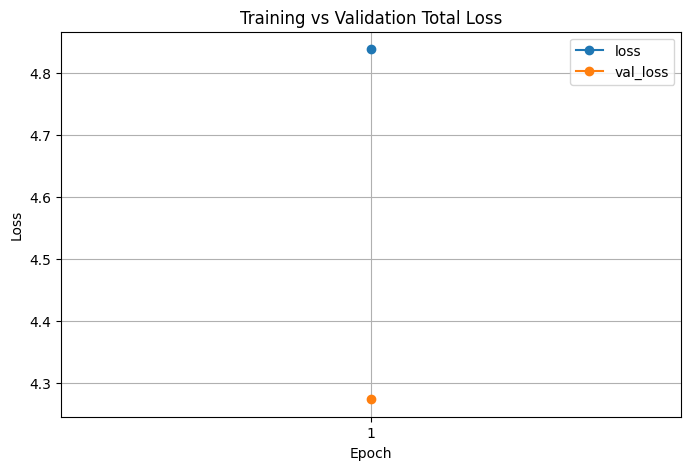

Caption Loss
Train: [3.9560461044311523]
Val: [3.464071273803711]


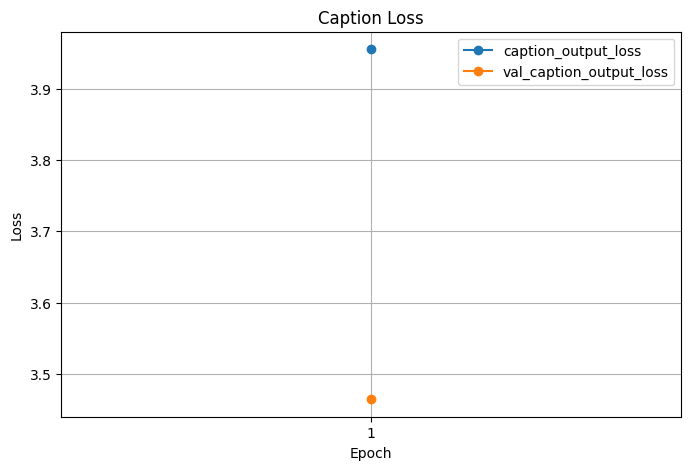

Classification Loss
Train: [2.9422316551208496]
Val: [2.6973142623901367]


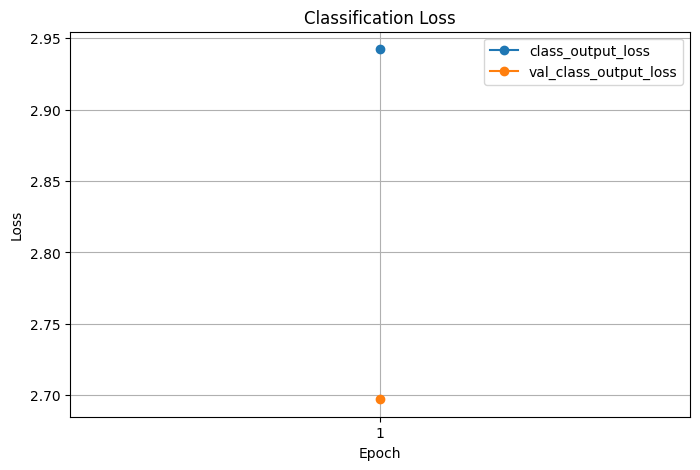

In [22]:
import matplotlib.pyplot as plt

def plot_metric(train_key, val_key, title, ylabel):
    train_values = history.history[train_key]
    val_values = history.history[val_key]

    print(title)
    print("Train:", train_values)
    print("Val:", val_values)

    plt.figure(figsize=(8, 5))
    plt.plot(range(1, len(train_values) + 1), train_values, marker="o", label=train_key)
    plt.plot(range(1, len(val_values) + 1), val_values, marker="o", label=val_key)
    plt.title(title)
    plt.xlabel("Epoch")
    plt.ylabel(ylabel)
    plt.xticks(range(1, len(train_values) + 1))
    plt.legend()
    plt.grid(True)
    plt.show()

plot_metric("loss", "val_loss", "Training vs Validation Total Loss", "Loss")
plot_metric("caption_output_loss", "val_caption_output_loss", "Caption Loss", "Loss")
plot_metric("class_output_loss", "val_class_output_loss", "Classification Loss", "Loss")

## Converting Word Indices Back to Words

This cell creates a reverse vocabulary that maps numerical word indices back to actual words.  
This is needed during caption generation.

In [23]:
index_to_word = {index: word for word, index in tokenizer.word_index.items()}

def idx_to_word(idx):
    return index_to_word.get(idx, None)

## Caption Generation Function

This function generates a caption one word at a time.  
It starts with the `<start>` token, predicts the next word, adds it to the caption, and stops when `<end>` is predicted.

In [24]:
def generate_caption(model, tokenizer, photo_feature, max_length):
    in_text = "<start>"

    for _ in range(max_length):
        sequence = tokenizer.texts_to_sequences([in_text])[0]
        sequence = pad_sequences([sequence], maxlen=max_length)

        predictions = model.predict(
            {
                "image_input": np.array([photo_feature]),
                "text_input": sequence
            },
            verbose=0
        )

        if isinstance(predictions, (list, tuple)):
            yhat = predictions[0]
        else:
            yhat = predictions

        yhat = np.argmax(yhat)
        word = idx_to_word(yhat)

        if word is None:
            break

        in_text += " " + word

        if word == "<end>":
            break

    return in_text

def predict_image_class(model, photo_feature):
    predictions = model.predict(
        {
            "image_input": np.array([photo_feature]),
            "text_input": np.zeros((1, max_length), dtype=int)
        },
        verbose=0
    )
    class_probs = predictions[1]
    class_idx = int(np.argmax(class_probs, axis=1)[0])
    return index_to_category_name[class_idx]

## Testing Caption Generation on Sample Images

This cell generates captions for a few sample test images and compares them with the ground truth captions.  
This gives a qualitative view of how well the model performs.

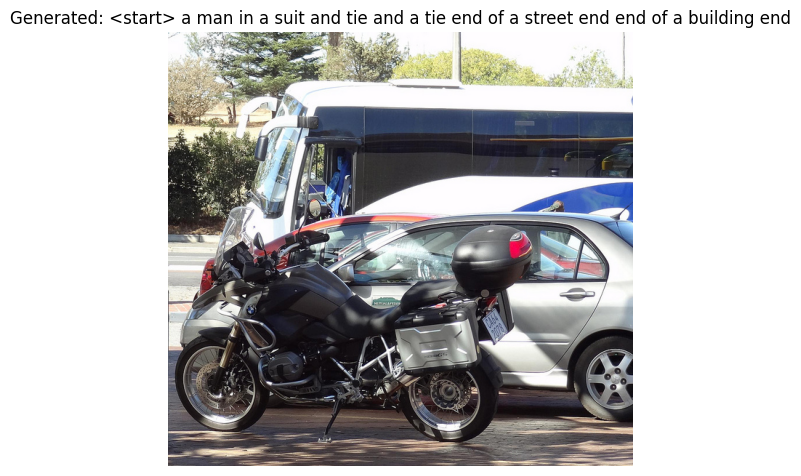

Predicted class: person
True class: car
References:
- <start> a motorcycle sitting in front of a car and a bus <end>
- <start> a bmw motorcycle parked next to a silver car <end>
- <start> there are different kind of cars parking at the parking place <end>


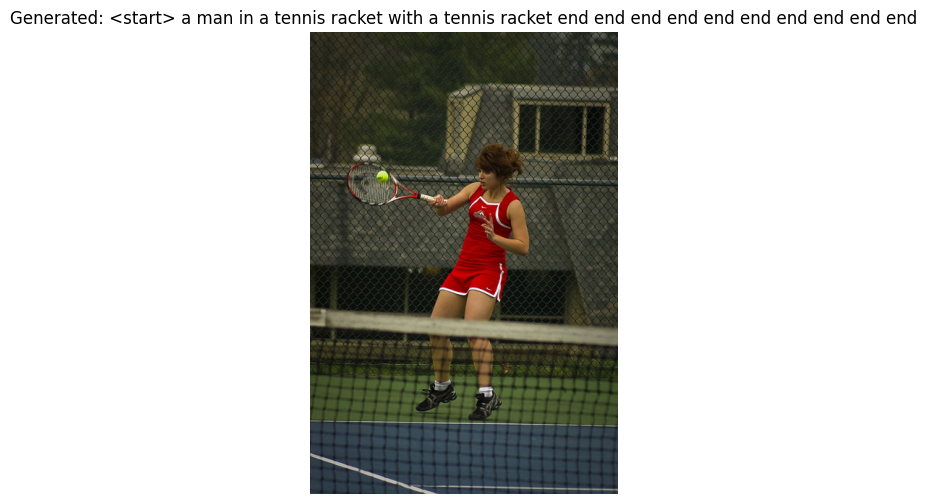

Predicted class: person
True class: sports ball
References:
- <start> a woman standing on a tennis court holding a racquet <end>
- <start> a woman wearing a red tennis outfit holds her racket out to the side near a tennis ball on a tennis court <end>
- <start> a tennis player hitting a ball on the tennis court <end>


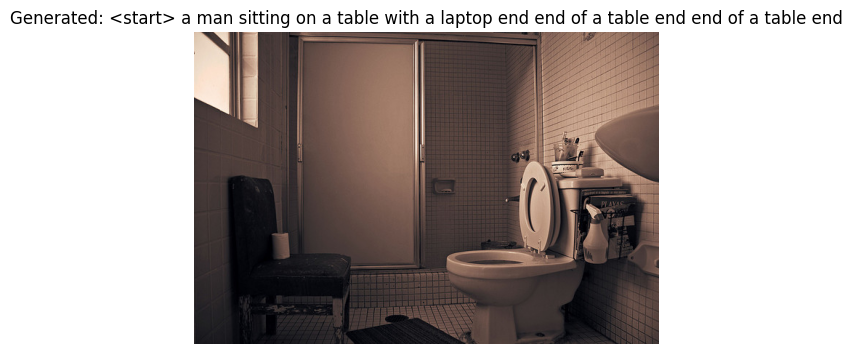

Predicted class: person
True class: toothbrush
References:
- <start> a white tiled bathroom with a walk in shower <end>
- <start> a toilet shower stall and chair in wash room <end>
- <start> a chair is sitting directly across from the toilet <end>


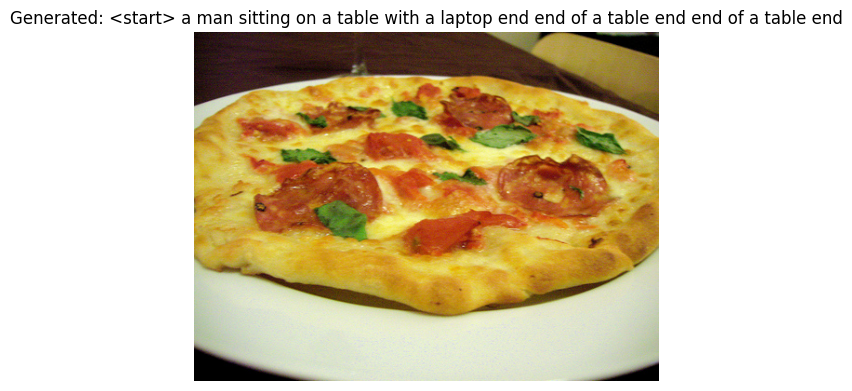

Predicted class: person
True class: pizza
References:
- <start> a pizza sitting on top of a white plate covered in toppings <end>
- <start> a pizza is on a white plate with pepperoni cheese and herbs <end>
- <start> a personal pizza sits on a white plate <end>


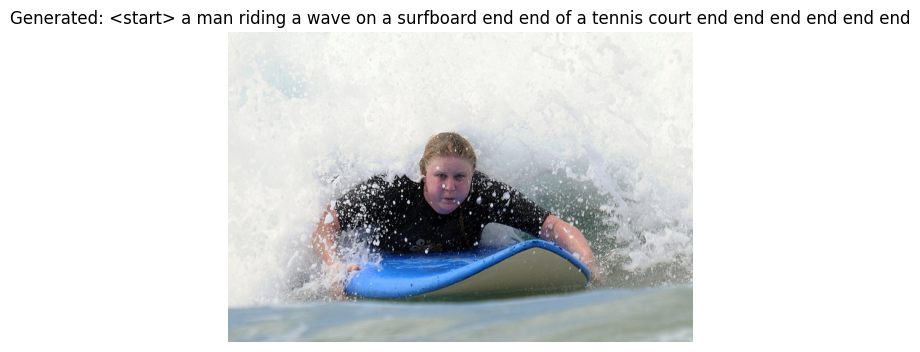

Predicted class: person
True class: person
References:
- <start> a young man riding on top of a surfboard in the ocean <end>
- <start> a person riding a surf board on a body of water <end>
- <start> a body surfer on his board riding a large wave <end>


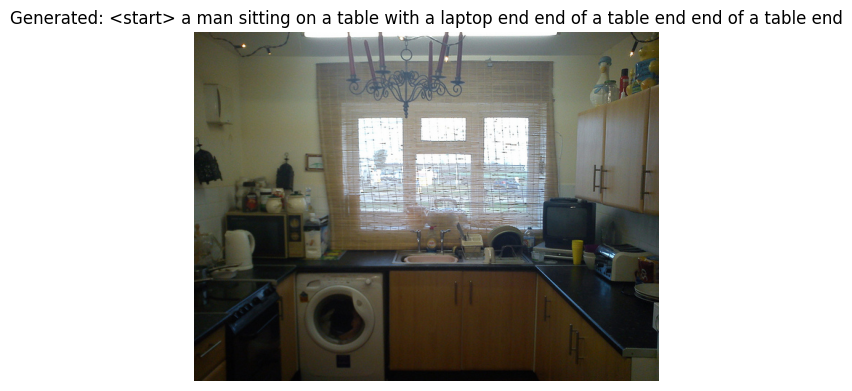

Predicted class: person
True class: bottle
References:
- <start> a kitchen with a washing machine under the counter <end>
- <start> a kitchen filled with appliances and a washer <end>
- <start> an image of a kitchen setting with washing machine installed <end>


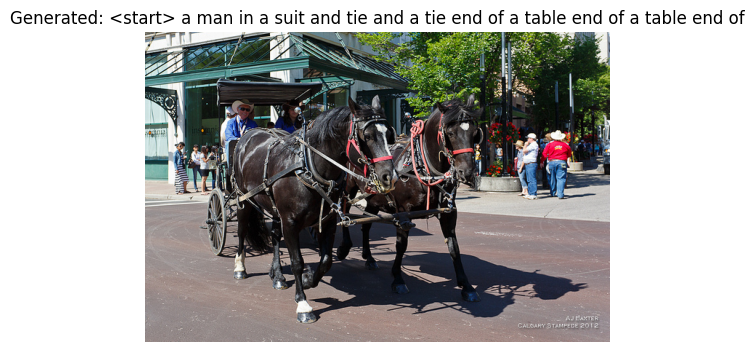

Predicted class: person
True class: person
References:
- <start> a couple of horses pulling a buggy down a road <end>
- <start> a pair of black horses pull a carriage <end>
- <start> two people in a carriage being pulled by two black horses <end>


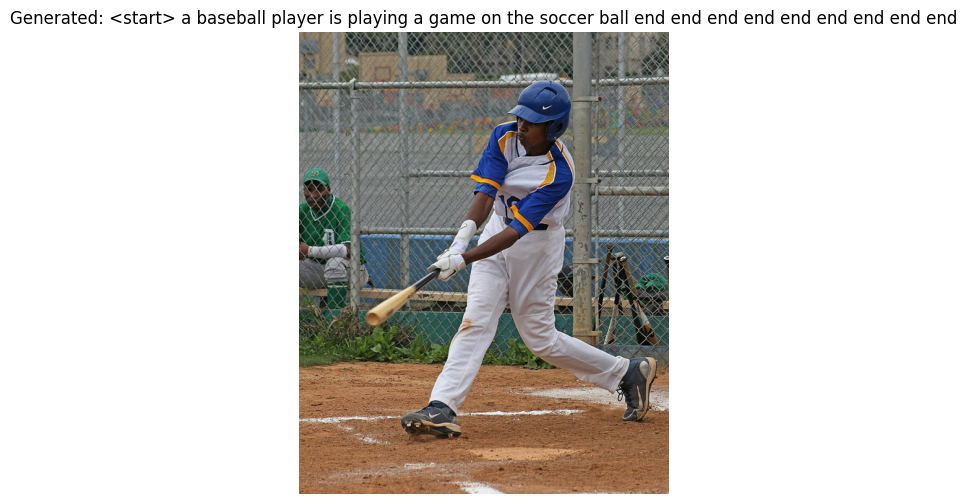

Predicted class: person
True class: baseball bat
References:
- <start> a young male baseball player swinging a bat <end>
- <start> a boy in blue and white uniform playing a game of baseball <end>
- <start> a male baseball player swings his bat forecfully <end>


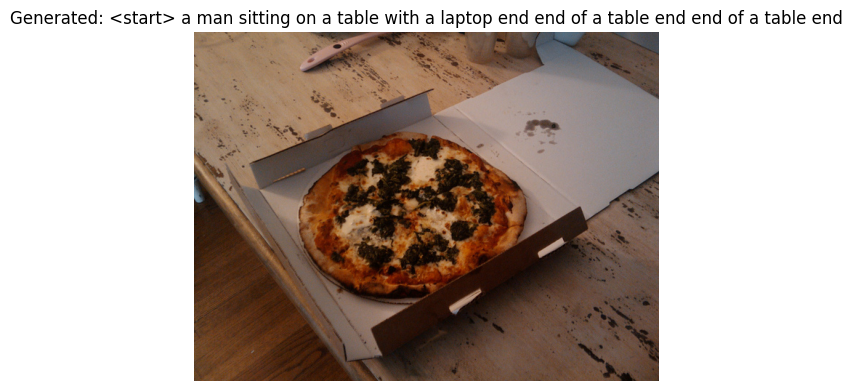

Predicted class: person
True class: pizza
References:
- <start> a pizza sits on a table in a pizza box <end>
- <start> a box of pizza sitting on the counter <end>
- <start> a small pizza in a box on a table <end>


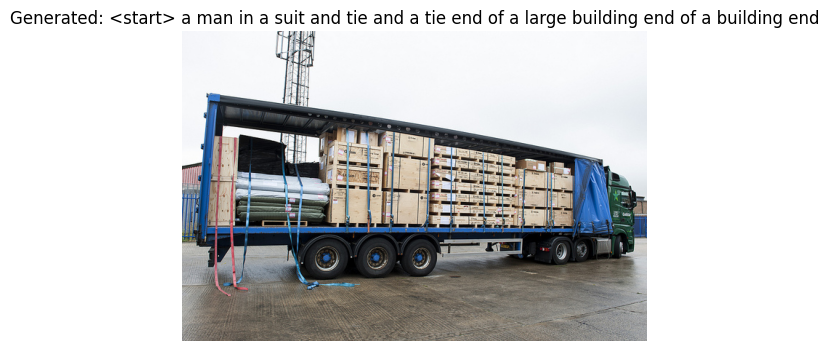

Predicted class: person
True class: truck
References:
- <start> side view of a large delivery truck packed with items sitting in a lot <end>
- <start> a truck with iuts trailer exposed showing its contents <end>
- <start> cargo truck with pallets and crates with blue cover drawn <end>


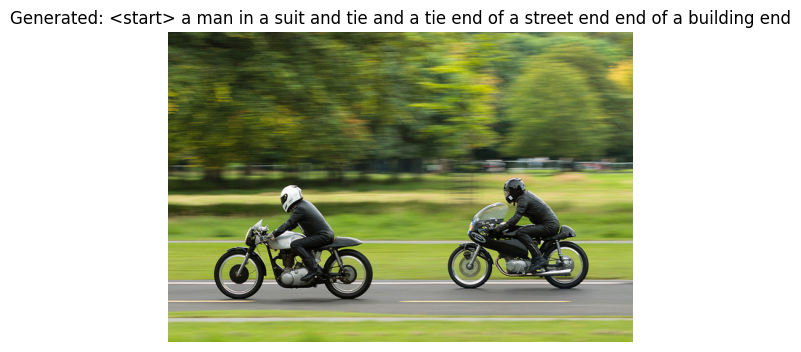

Predicted class: person
True class: motorcycle
References:
- <start> a couple of men riding on the back of motorcycles <end>
- <start> some people are riding their motorcycles on the streets <end>
- <start> two men are driving motorcycles fast down a road <end>


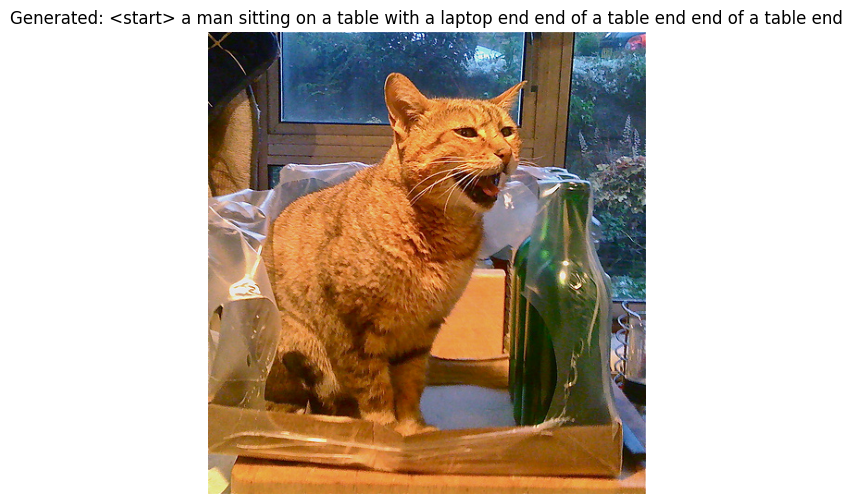

Predicted class: person
True class: bottle
References:
- <start> a cat is sitting in a box with its mouth open <end>
- <start> a cat sits inside a plasticwrapped box with its mouth open <end>
- <start> an orange cat sits on a table yawning <end>


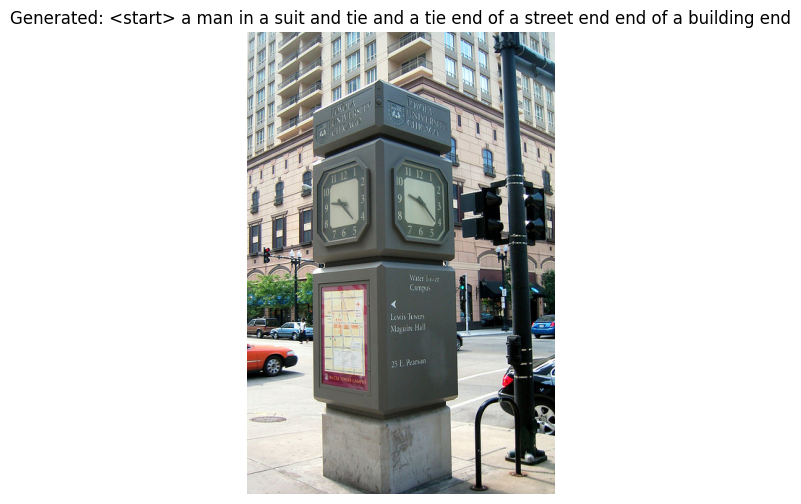

Predicted class: person
True class: car
References:
- <start> a stone top with a clock inside of it <end>
- <start> a sculpture is on a street with a clock and a city map on the sides <end>
- <start> a clock on the side of the street with a street map <end>


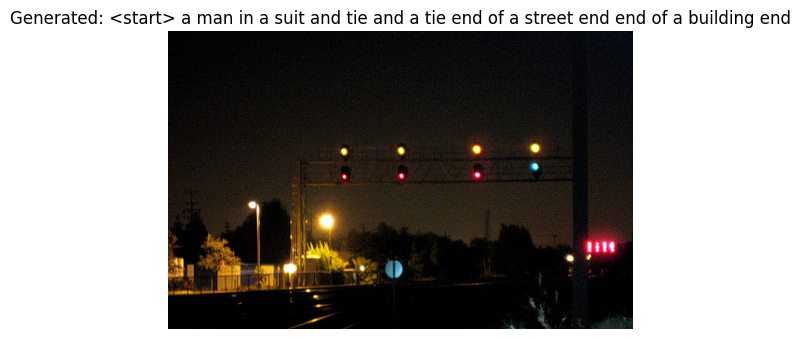

Predicted class: person
True class: traffic light
References:
- <start> traffic lights hang above train tracks at night <end>
- <start> night time at a railroad crossing yellow red and green lights shown above <end>
- <start> the colorful lights are illuminating the darkened street <end>


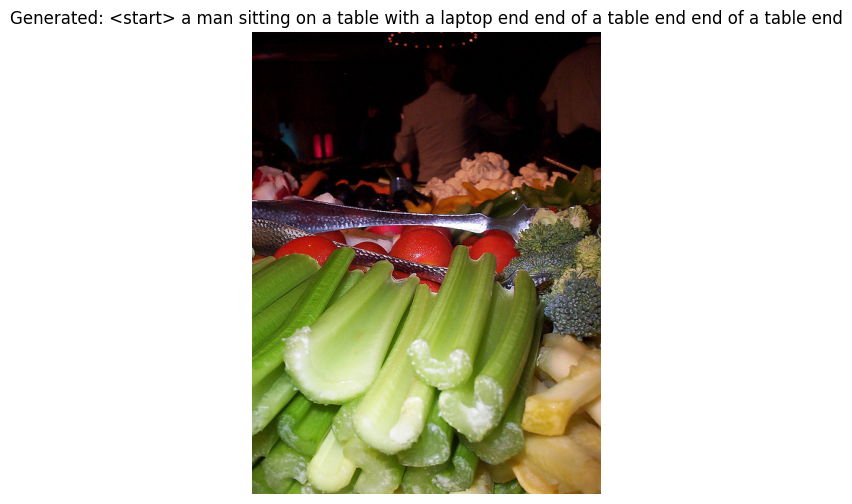

Predicted class: person
True class: person
References:
- <start> celery broccoli tomatoes and other various vegetables cut on table <end>
- <start> a pile of celery sitting next to piles of other vegetables <end>
- <start> a bunch of vegetables and other foods are laying out <end>


In [25]:
sample_files = test_df["file_name"].drop_duplicates().sample(min(15, test_df["file_name"].nunique()), random_state=42).tolist()

for file_name in sample_files:
    img_path = os.path.join("train_images_subset", file_name)
    img = Image.open(img_path)

    plt.figure(figsize=(6,6))
    plt.imshow(img)
    plt.axis("off")

    yhat = generate_caption(model, tokenizer, features[file_name], max_length)
    predicted_class = predict_image_class(model, features[file_name])
    true_class = test_df[test_df["file_name"] == file_name]["category_name"].iloc[0]
    captions = test_df[test_df["file_name"] == file_name]["clean_caption"].tolist()

    plt.title("Generated: " + yhat)
    plt.show()

    print("Predicted class:", predicted_class)
    print("True class:", true_class)
    print("References:")
    for c in captions[:3]:
        print("-", c)
    print("="*80)

## Quantitative Evaluation Using BLEU Score

This cell evaluates the generated captions using BLEU score.  
BLEU compares the generated captions with the real human-written captions.

BLEU-1 measures word-level similarity, while BLEU-4 measures longer phrase similarity.

In [26]:
!pip install nltk -q
from nltk.translate.bleu_score import corpus_bleu

actual, predicted = [], []
class_true, class_pred = [], []

eval_files = test_df["file_name"].drop_duplicates().tolist()
if DEBUG:
    eval_files = eval_files[:100]

for file_name in tqdm(eval_files):
    yhat = generate_caption(model, tokenizer, features[file_name], max_length)

    refs = test_df[test_df["file_name"] == file_name]["clean_caption"].tolist()
    refs = [r.replace("<start>", "").replace("<end>", "").split() for r in refs]

    pred = yhat.replace("<start>", "").replace("<end>", "").split()

    actual.append(refs)
    predicted.append(pred)

    true_class_idx = int(test_df[test_df["file_name"] == file_name]["class_idx"].iloc[0])
    pred_class_name = predict_image_class(model, features[file_name])
    pred_class_idx = [k for k, v in index_to_category_name.items() if v == pred_class_name][0]

    class_true.append(true_class_idx)
    class_pred.append(pred_class_idx)

class_accuracy = np.mean(np.array(class_true) == np.array(class_pred))

print("BLEU-1:", corpus_bleu(actual, predicted, weights=(1.0, 0, 0, 0)))
print("BLEU-2:", corpus_bleu(actual, predicted, weights=(0.5, 0.5, 0, 0)))
print("BLEU-3:", corpus_bleu(actual, predicted, weights=(0.33, 0.33, 0.33, 0)))
print("BLEU-4:", corpus_bleu(actual, predicted, weights=(0.25, 0.25, 0.25, 0.25)))
print("Classification accuracy:", class_accuracy)

100%|██████████| 100/100 [07:47<00:00,  4.67s/it]


BLEU-1: 0.2825
BLEU-2: 0.16763447076742202
BLEU-3: 0.09367087476516472
BLEU-4: 0.04605749644270328
Classification accuracy: 0.26


## Final Discussion

The project successfully implements the required CNN-RNN image captioning pipeline.

The model does not use attention mechanisms, which limits its ability to focus on specific parts of the image when generating captions.

The notebook includes caption cleaning, tokenization, vocabulary construction, sequence preparation, CNN feature extraction, RNN-based caption generation, auxiliary image classification, and BLEU evaluation.

The model can generate captions, but the quality is limited because training deep image captioning models requires high computational power and more epochs.

Future improvements could include:
- Training for more epochs
- Using a larger dataset
- Adding an attention mechanism
- Using transformer-based models for better caption generation

## Conclusion

In this project, a CNN–RNN architecture was successfully implemented to generate captions for images from the MS COCO dataset.  
The CNN (InceptionV3) extracts meaningful visual features, while the RNN (LSTM) generates captions word by word based on these features.

The model also includes an auxiliary image classification task, which helps improve feature learning and enhances caption relevance.  
Both qualitative results (generated captions) and quantitative evaluation (BLEU score) show that the model is able to learn basic relationships between images and language.

However, due to limited training time and computational resources, the model performance is not optimal, and the generated captions may lack fluency or detail.

Overall, the project demonstrates how deep learning can be used to bridge computer vision and natural language processing.  
Future improvements could include training for more epochs, using a larger dataset, and applying advanced techniques such as attention mechanisms or transformer-based models.